# **_E-Commerce Delivery Delay Analysis_**  

**Team Members: Logan Clevenger and Charlie Ring**  
**Gonzaga University**  
**CPSC 322, Fall 2026**  

In [274]:
# Standard libraries
import random
import math
import copy
import importlib
from tabulate import tabulate

# Data visualization
import matplotlib.pyplot as plt

# Project modules
from mysklearn.mypytable import MyPyTable
from mysklearn import myevaluation
from mysklearn import myutils
from mysklearn import myclassifiers

# Reloading
importlib.reload(myevaluation)
importlib.reload(myutils)
importlib.reload(myclassifiers)

<module 'mysklearn.myclassifiers' from 'c:\\Users\\logan\\CPSC-322-Coding-Assignments\\cpsc322-ecommerce-shipping-project\\mysklearn\\myclassifiers.py'>

## **Introduction**

## **Data Analysis**

Before we can make use of the data, we must load it into a MyPyTable from the input file `initial_ecommerce_data.csv`. From there, to get a partial visualization for the new MyPyTable we can print out the first 5 instances.

In [275]:
ecommerce_table = MyPyTable()
ecommerce_table.load_from_file("input_data/initial_ecommerce_data.csv")

print(tabulate(
    [row[:5] for row in ecommerce_table.data[:5]],
    headers=ecommerce_table.column_names[:5],
    tablefmt="grid"
))


+------+-------------------+--------------------+-----------------------+-------------------+
|   ﻿ID | Warehouse_block   | Mode_of_Shipment   |   Customer_care_calls |   Customer_rating |
+======+===================+====================+=======================+===================+
|    1 | D                 | Flight             |                     4 |                 2 |
+------+-------------------+--------------------+-----------------------+-------------------+
|    2 | F                 | Flight             |                     4 |                 5 |
+------+-------------------+--------------------+-----------------------+-------------------+
|    3 | A                 | Flight             |                     2 |                 2 |
+------+-------------------+--------------------+-----------------------+-------------------+
|    4 | B                 | Flight             |                     3 |                 3 |
+------+-------------------+--------------------+----------

Looking at the initial features of this data, we will remove the `ID` attribute. We will do this as this attribute will be trivial for our predictions since it is just an instance identifier.

Also, upon further inspection, it seems our initial CSV data was saved using UTF-8 with BOM encoding. As such, special characters are currently attached to the `ID` attribute column name. Due to how our MyPyTable `load_from_file()` function works, this encoding was not stripped yet. To remedy this, we will use the `repr()` function to identify the special characters and then remove the `ID` column using this complete string to identify the `ID` index within our table.

To check if the removal was successful, we once again will print out the first 5 instances within our data (just the first 5 attributes to prevent display wrapping).

In [276]:
print(repr(ecommerce_table.column_names[0]))
id_index = ecommerce_table.column_names.index("\ufeffID")

for row in ecommerce_table.data:
    row.pop(id_index)

ecommerce_table.column_names.pop(id_index)

print(tabulate(
    [row[:5] for row in ecommerce_table.data[:5]],
    headers=ecommerce_table.column_names[:5],
    tablefmt="grid"
))

'\ufeffID'
+-------------------+--------------------+-----------------------+-------------------+-----------------------+
| Warehouse_block   | Mode_of_Shipment   |   Customer_care_calls |   Customer_rating |   Cost_of_the_Product |
+===================+====================+=======================+===================+=======================+
| D                 | Flight             |                     4 |                 2 |                   177 |
+-------------------+--------------------+-----------------------+-------------------+-----------------------+
| F                 | Flight             |                     4 |                 5 |                   216 |
+-------------------+--------------------+-----------------------+-------------------+-----------------------+
| A                 | Flight             |                     2 |                 2 |                   183 |
+-------------------+--------------------+-----------------------+-------------------+---------------

Within our initial inspection of the available attributes, we discovered a few that may pose a data leakage issue within our model: `Customer_care_calls` and `Customer_rating`. These attributes were likely recorded AFTER the company has already shipped the product for that instance. As we are trying to create a model used in predicting the timeliness of product delivery BEFORE shipping, including these attributes in model training will pose an issue.

To fix this, we will remove these attributes from the data. To check if this was successful, we will once again print out the first 5 instances for a partial view of the data.

In [277]:
calls_index = ecommerce_table.column_names.index("Customer_care_calls")
rating_index = ecommerce_table.column_names.index("Customer_rating")

for row in ecommerce_table.data:
    row.pop(calls_index)
    row.pop(rating_index - 1)

ecommerce_table.column_names.pop(calls_index)
ecommerce_table.column_names.pop(rating_index - 1)

print(tabulate(
    [row[:5] for row in ecommerce_table.data[:5]],
    headers=ecommerce_table.column_names[:5],
    tablefmt="grid"
))

+-------------------+--------------------+-----------------------+-------------------+----------------------+
| Warehouse_block   | Mode_of_Shipment   |   Cost_of_the_Product |   Prior_purchases | Product_importance   |
+===================+====================+=======================+===================+======================+
| D                 | Flight             |                   177 |                 3 | low                  |
+-------------------+--------------------+-----------------------+-------------------+----------------------+
| F                 | Flight             |                   216 |                 2 | low                  |
+-------------------+--------------------+-----------------------+-------------------+----------------------+
| A                 | Flight             |                   183 |                 4 | low                  |
+-------------------+--------------------+-----------------------+-------------------+----------------------+
| B       

From here, we can begin to explore our viable data. To get a better idea of each of our attributes, we can evaluate frequencies of our categorical attributes and also look into summary statistics for our numerical attributes.

In [278]:
numerical_attr = [
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms"
]

print("ATTRIBUTE FREQUENCY AND SUMMARY STATS")
total_instances = len(ecommerce_table.data)
print(f"Total instances in dataset: {total_instances}\n\n")

for attr in ecommerce_table.column_names:
    print(f"Attribute: {attr}")
    if attr not in numerical_attr:
        attr_lst = ecommerce_table.get_column(attr)
        frequency_dict = myutils.get_value_counts(attr_lst)

        for value, occurrences in frequency_dict.items():
            proportion = occurrences / total_instances
            print(f"Value: {value}, Occurred: {occurrences}, Proportion: {proportion:.4f}")
    else:
        stats = ecommerce_table.compute_summary_statistics([attr])
        data = stats.data[0]
        print(f"Minimum: {data[1]}")
        print(f"Maximum: {data[2]}")
        print(f"Midrange: {data[3]}")
        print(f"Average: {data[4]:.4f}")
        print(f"Median: {data[5]}")

    print("------------------------------------------------\n")


ATTRIBUTE FREQUENCY AND SUMMARY STATS
Total instances in dataset: 10999


Attribute: Warehouse_block
Value: D, Occurred: 1834, Proportion: 0.1667
Value: F, Occurred: 3666, Proportion: 0.3333
Value: A, Occurred: 1833, Proportion: 0.1667
Value: B, Occurred: 1833, Proportion: 0.1667
Value: C, Occurred: 1833, Proportion: 0.1667
------------------------------------------------

Attribute: Mode_of_Shipment
Value: Flight, Occurred: 1777, Proportion: 0.1616
Value: Ship, Occurred: 7462, Proportion: 0.6784
Value: Road, Occurred: 1760, Proportion: 0.1600
------------------------------------------------

Attribute: Cost_of_the_Product
Minimum: 96.0
Maximum: 310.0
Midrange: 203.0
Average: 210.1968
Median: 214.0
------------------------------------------------

Attribute: Prior_purchases
Minimum: 2.0
Maximum: 10.0
Midrange: 6.0
Average: 3.5676
Median: 3.0
------------------------------------------------

Attribute: Product_importance
Value: low, Occurred: 5297, Proportion: 0.4816
Value: medium, Occu

##### **Observations By Attribute**
After looking through the summary report of each attribute, here is **_what stood out_**:

1. **Warehouse_block** 
    - $\frac{1}{3}$ of all products shipped by this company originate from warehouse block F
2. **Mode_of_shipment**
    - Almost 68% of all products were shipped by ship rather than flight or road
3. **Cost_of_the_product**
    - Median cost of the product is $214 USD
4. **Prior_purchases**
    - Minimum value is 2, meaning all customers in this dataset are returning customers
5. **Product_importance**
    - Values of `low` and `medium` occurred in relatively close frequencies with `high` occurring FAR less
6. **Gender**
    - Customers seem to be evenly split by reported gender in this dataset 
7. **Discount_offered**
    - The average discount sits around 13.37 with a median of 7.0. This suggests a rightwards skew in consideration of the value range for this attribute
8. **Weight_in_gms**
    - None of the products shipped by this company are that heavy for a freight shipment, with a max of 7846.0 grams = 17.3 lbs
9. **Reached.on.Time_Y.N**
    - The classes ARE imbalanced, with about 60% of deliveries being reported as delayed

Now we can take the data, and create a training and testing set utilizing a random stratified subsample. This will later be used when we begin to train and evaluate our chosen models.

In [279]:
X = []
y = ecommerce_table.get_column("Reached.on.Time_Y.N")

on_time_index = ecommerce_table.column_names.index("Reached.on.Time_Y.N")

for row in ecommerce_table.data:
    row_cpy = row.copy()
    row_cpy.pop(on_time_index)
    X.append(row_cpy)

train_ind, test_ind = myevaluation.random_stratified_subsample(X, y, test_size=0.33, random_state=0)

X_train = []
y_train = []
for index in train_ind:
    row_cpy = ecommerce_table.data[index].copy()
    y_train.append(row_cpy.pop(on_time_index))
    X_train.append(row_cpy)

X_test = []
y_test = []
for index in test_ind:
    row_cpy = ecommerce_table.data[index].copy()
    y_test.append(row_cpy.pop(on_time_index))
    X_test.append(row_cpy)

To dive deeper into exploring our data, we can create visuals to help us further understand and grasp characteristics not inherently obvious from looking into frequencies and summary statistics alone. First, we can utilize a bar chart to visualize the class imbalance within our dataset. See *Figure 1* below:

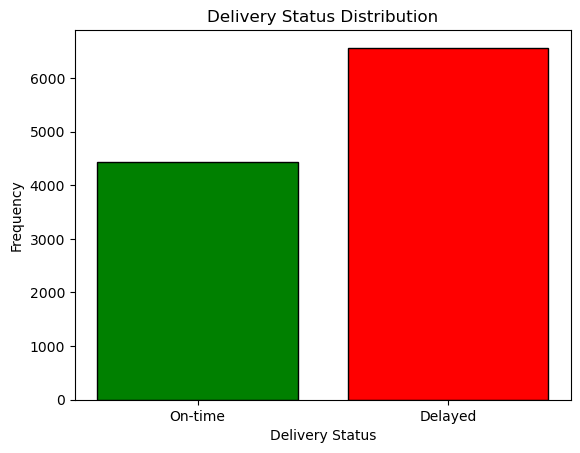

In [280]:
# BAR CHART - Delivery Status Distribution
plt.figure()
labels = ["On-time", "Delayed"]
counts = [4436, 6563]

plt.bar(labels, counts, color=["green", "red"], edgecolor="black", linewidth=1.0)
plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Frequency")
plt.savefig("output_data/delivery_status_distr.png")
plt.show()

*Figure 1: Class Distribution of On-time and Delayed Shipments*

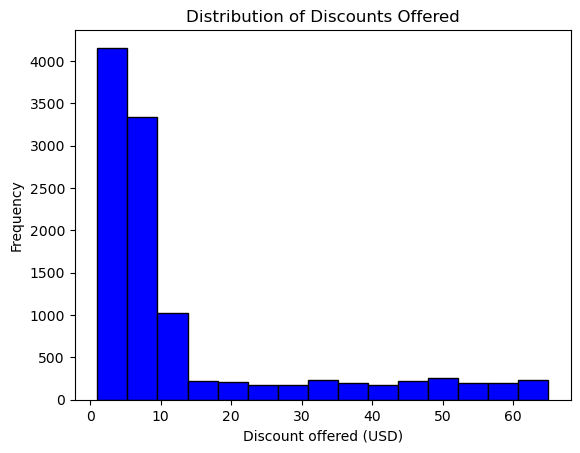

In [281]:
# Histogram - Discounts
discounts = ecommerce_table.get_column("Discount_offered")
plt.figure()
plt.hist(discounts, bins=15, color="blue", edgecolor="black", linewidth=1.0)
plt.title("Distribution of Discounts Offered")
plt.xlabel("Discount offered (USD)")
plt.ylabel("Frequency")
plt.savefig("output_data/discount_frequency.png")
plt.show()


*Figure 2: Frequency Distribution of Discounts Offered (in USD)*

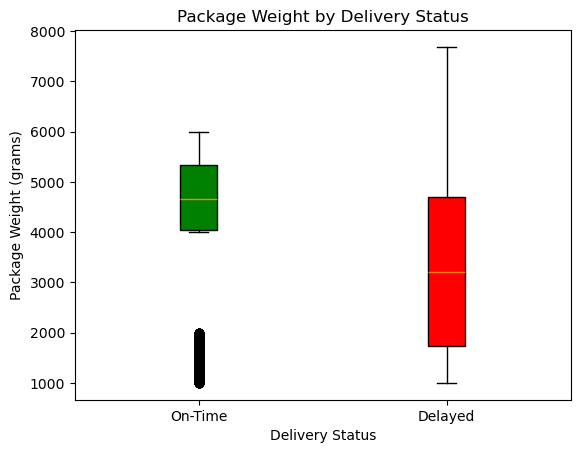

In [282]:
weight_index = ecommerce_table.column_names.index("Weight_in_gms")
weights_on_time = []
weights_delayed = []
for i, label in enumerate(y_train):
    if label == 1:
        weights_delayed.append(X_train[i][weight_index])
    else:
        weights_on_time.append(X_train[i][weight_index])

plt.figure()
boxes = plt.boxplot([weights_on_time, weights_delayed], tick_labels=["On-Time", "Delayed"], patch_artist=True)
boxes["boxes"][0].set_facecolor("green")
boxes["boxes"][1].set_facecolor("red")
plt.title("Package Weight by Delivery Status")
plt.ylabel("Package Weight (grams)")
plt.xlabel("Delivery Status")
plt.savefig("output_data/package_weight_delivery_status.png")
plt.show()


*Figure 3: Distribution of Package Weights by Delivery Status*

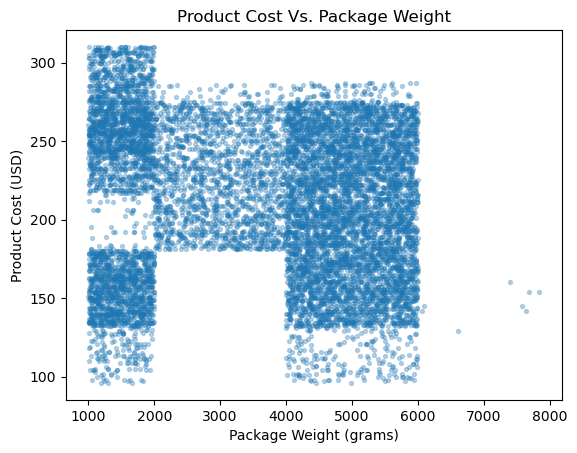

In [283]:
# Scatterplot (product cost vs. package weight)
product_cost = ecommerce_table.get_column("Cost_of_the_Product")
package_weight = ecommerce_table.get_column("Weight_in_gms")

plt.figure()
plt.scatter(package_weight, product_cost, s=8, alpha=0.3)
plt.title("Product Cost Vs. Package Weight")
plt.xlabel("Package Weight (grams)")
plt.ylabel("Product Cost (USD)")
plt.show()

*Figure 4: Relationship Between Product Cost and Package Weight*

## **Classifications**

The first classifier we have chosen to utilize is a _Naive Bayes_ classifier. This classifier is based on the scikit-learn implementation. We will first fit the classifier to the training data, then we will use this trained model to make predictions on the test data. From there, we will use different performance metrics to evaluate the success of the classifier.

In [284]:
naive_bayes = myclassifiers.MyNaiveBayesClassifier()
naive_bayes.fit(X_train, y_train)
y_predicted = naive_bayes.predict(X_test)

nb_confusion_matrix = myevaluation.confusion_matrix(y_test, y_predicted, [0,1])
print("NAIVE BAYES MODEL CONFUSION MATRIX:")
print(tabulate(
    nb_confusion_matrix,
    headers=["Predicted On-Time", "Predicted Delayed"],
    showindex=["Actual On-Time", "Actual Delayed"],
    tablefmt="grid"
))
accuracy = myevaluation.accuracy_score(y_test, y_predicted, normalize=True)
error = 1 - accuracy
precision = myevaluation.binary_precision_score(y_test, y_predicted, [0, 1], 1)
recall = myevaluation.binary_recall_score(y_test, y_predicted, [0, 1], 1)
f1_score = myevaluation.binary_f1_score(y_test, y_predicted, [0, 1], 1)
print("Further Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Error Rate: {error:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1_score:.4f}")

NAIVE BAYES MODEL CONFUSION MATRIX:
+----------------+---------------------+---------------------+
|                |   Predicted On-Time |   Predicted Delayed |
+================+=====================+=====================+
| Actual On-Time |                 788 |                 676 |
+----------------+---------------------+---------------------+
| Actual Delayed |                 648 |                1518 |
+----------------+---------------------+---------------------+
Further Evaluation Metrics:
Accuracy: 0.6353
Error Rate: 0.3647
Precision: 0.6919
Recall: 0.7008
F1 Score: 0.6963


## **Classification Results**

## **Conclusion**

## **Acknowledgements**